# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Exploratory Data Analysis 

In [91]:
# Lectura datos, relación variables, mapas de correlación...
ingresos = pd.read_csv('data/Advertising.csv', delimiter=',')

ingresos.head()

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0


In [92]:
ingresos.describe()

,Unnamed: 0,TV,radio,sales
count,200.000000,200.000000,200.000000,200.000000
mean,99.500000,147.042500,23.264000,14022.500000
std,57.879185,85.854236,14.846809,5217.456566
min,0.000000,0.700000,0.000000,1600.000000
25%,49.750000,74.375000,9.975000,10375.000000
50%,99.500000,149.750000,22.900000,12900.000000
75%,149.250000,218.825000,36.525000,17400.000000
max,199.000000,296.400000,49.600000,27000.000000


In [93]:
ingresos.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newpaper    200 non-null    str    
 4   sales       200 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 7.9 KB


In [94]:
ingresos = ingresos.drop(columns=['Unnamed: 0'])
ingresos

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0
...,...,...,...,...
195,38.2,3.7,13.8,7600.0
196,94.2,4.9,8.1,9700.0
197,177.0,9.3,6.4,12800.0
198,283.6,42.0,66.2,25500.0


In [95]:
ingresos = ingresos.replace('6s9.2', '69.9').astype(float)

In [96]:
ingresos.value_counts()

TV     radio  newpaper  sales  
230.1  37.8   69.9      22100.0    1
44.5   39.3   45.1      10400.0    1
17.2   45.9   69.3      9300.0     1
151.5  41.3   58.5      18500.0    1
180.8  10.8   58.4      12900.0    1
                                  ..
38.2   3.7    13.8      7600.0     1
94.2   4.9    8.1       9700.0     1
177.0  9.3    6.4       12800.0    1
283.6  42.0   66.2      25500.0    1
232.1  8.6    8.7       13400.0    1
Name: count, Length: 200, dtype: int64

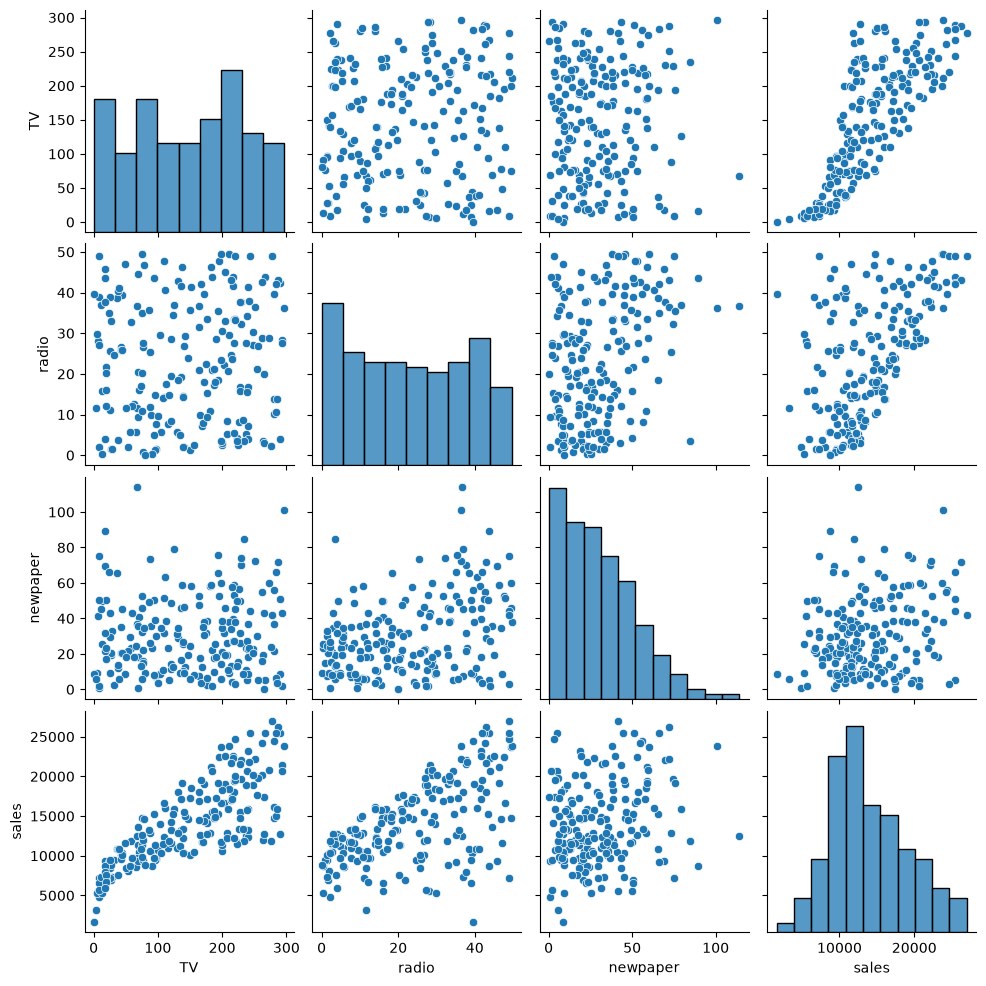

In [97]:
sns.pairplot(ingresos);

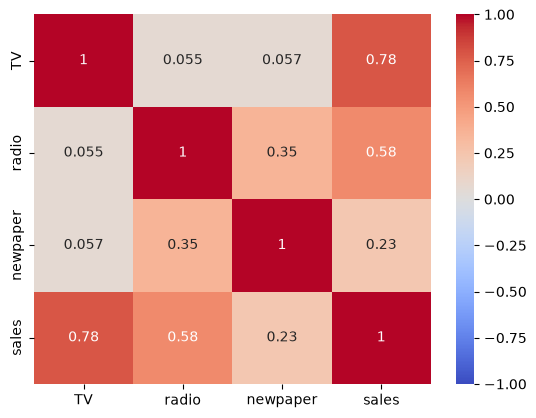

In [98]:
sns.heatmap(ingresos.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1);

## Modelado

In [99]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.
X = np.array(ingresos.drop(columns=['sales']))
y = np.array(ingresos['sales'])

In [100]:
X

array([[230.1,  37.8,  69.9],
       [ 44.5,  39.3,  45.1],
       [ 17.2,  45.9,  69.3],
       [151.5,  41.3,  58.5],
       [180.8,  10.8,  58.4],
       [  8.7,  48.9,  75. ],
       [ 57.5,  32.8,  23.5],
       [120.2,  19.6,  11.6],
       [  8.6,   2.1,   1. ],
       [199.8,   2.6,  21.2],
       [ 66.1,   5.8,  24.2],
       [214.7,  24. ,   4. ],
       [ 23.8,  35.1,  65.9],
       [ 97.5,   7.6,   7.2],
       [204.1,  32.9,  46. ],
       [195.4,  47.7,  52.9],
       [ 67.8,  36.6, 114. ],
       [281.4,  39.6,  55.8],
       [ 69.2,  20.5,  18.3],
       [147.3,  23.9,  19.1],
       [218.4,  27.7,  53.4],
       [237.4,   5.1,  23.5],
       [ 13.2,  15.9,  49.6],
       [228.3,  16.9,  26.2],
       [ 62.3,  12.6,  18.3],
       [262.9,   3.5,  19.5],
       [142.9,  29.3,  12.6],
       [240.1,  16.7,  22.9],
       [248.8,  27.1,  22.9],
       [ 70.6,  16. ,  40.8],
       [292.9,  28.3,  43.2],
       [112.9,  17.4,  38.6],
       [ 97.2,   1.5,  30. ],
       [26

In [101]:
y

array([22100., 10400.,  9300., 18500., 12900.,  7200., 11800., 13200.,
        4800., 10600.,  8600., 17400.,  9200.,  9700., 19000., 22400.,
       12500., 24400., 11300., 14600., 18000., 12500.,  5600., 15500.,
        9700., 12000., 15000., 15900., 18900., 10500., 21400., 11900.,
        9600., 17400.,  9500., 12800., 25400., 14700., 10100., 21500.,
       16600., 17100., 20700., 12900.,  8500., 14900., 10600., 23200.,
       14800.,  9700., 11400., 10700., 22600., 21200., 20200., 23700.,
        5500., 13200., 23800., 18400.,  8100., 24200., 15700., 14000.,
       18000.,  9300.,  9500., 13400., 18900., 22300., 18300., 12400.,
        8800., 11000., 17000.,  8700.,  6900., 14200.,  5300., 11000.,
       11800., 12300., 11300., 13600., 21700., 15200., 12000., 16000.,
       12900., 16700., 11200.,  7300., 19400., 22200., 11500., 16900.,
       11700., 15500., 25400., 17200., 11700., 23800., 14800., 14700.,
       20700., 19200.,  7200.,  8700.,  5300., 19800., 13400., 21800.,
      

In [102]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [103]:
print("Total features shape:", X.shape)
print("Train features shape:", X_train.shape)
print("Train target shape:", y_train.shape)
print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Total features shape: (200, 3)
Train features shape: (160, 3)
Train target shape: (160,)
Test features shape: (40, 3)
Test target shape: (40,)


In [104]:
#creating LinearRegression Object
lm = LinearRegression()

In [105]:
# Escalar. En este caso no es del todo necesario pero casi siempre es recomendable

In [106]:
#Training the Data Model
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 44.73,189.18, 2.78]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[1064.54, 272.84, 161.53]"


In [107]:
y_pred_train = lm.predict(X_train)
y_pred_test = lm.predict(X_test)

In [108]:
# MÉTRICAS TRAIN

print("----- TRAIN -----")

print("MAE:", mean_absolute_error(y_train, y_pred_train))
print("MSE:", mean_squared_error(y_train, y_pred_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_train)))
print("R2:", lm.score(X_train, y_train))


# MÉTRICAS TEST

print("\n----- TEST -----")

print("MAE:", mean_absolute_error(y_test, y_pred_test))
print("MSE:", mean_squared_error(y_test, y_pred_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test)))
print("R2:", lm.score(X_test, y_test))

----- TRAIN -----
MAE: 1198.4765246597776
MSE: 2705093.436921005
RMSE: 1644.7168257548183
R2: 0.8957022145868812

----- TEST -----
MAE: 1460.8694648545818
MSE: 3174361.928051206
RMSE: 1781.6739118175374
R2: 0.8994296418464325


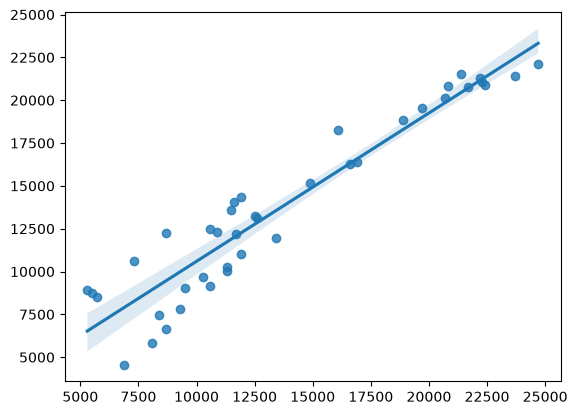

In [109]:
sns.regplot(x=y_test, y=y_pred_test);

### Modelos Polinómicos

In [110]:
poly = PolynomialFeatures(degree = 2)
poly.fit(X_train)
X_poly = poly.transform(X_train)
X_poly

# Ahora el modelo puede aprender una fórmula con una curva: y=aX^2+bX+c

array([[1.00000e+00, 1.16000e+02, 7.70000e+00, ..., 5.92900e+01,
        1.77870e+02, 5.33610e+02],
       [1.00000e+00, 1.77000e+02, 9.30000e+00, ..., 8.64900e+01,
        5.95200e+01, 4.09600e+01],
       [1.00000e+00, 4.31000e+01, 2.67000e+01, ..., 7.12890e+02,
        9.37170e+02, 1.23201e+03],
       ...,
       [1.00000e+00, 2.17700e+02, 3.35000e+01, ..., 1.12225e+03,
        1.97650e+03, 3.48100e+03],
       [1.00000e+00, 1.65600e+02, 1.00000e+01, ..., 1.00000e+02,
        1.76000e+02, 3.09760e+02],
       [1.00000e+00, 2.80200e+02, 1.01000e+01, ..., 1.02010e+02,
        2.16140e+02, 4.57960e+02]], shape=(160, 10))

In [111]:
from sklearn.linear_model import LinearRegression
poly_reg = LinearRegression() # Creamos el modelo
poly_reg.fit(X_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0. ,53.24,17.1 ,..., 0.13, 0.12, 0.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4939
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,9
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[324643.2 , 53795.37, 29264.65,..., 68. , 42.8 , 0. ]"


In [112]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
# Se usan las metricas para ver modelos y se hacen train y test

In [113]:
X_test_poly = poly.transform(X_test)
y_pred_poly = poly_reg.predict(X_test_poly)

baseline_error = mean_squared_error(y_test, y_pred_poly)

print("MAE:", mean_absolute_error(y_test, y_pred_poly ))
print("MSE:", mean_squared_error(y_test, y_pred_poly ))
print("r2_score test",poly_reg.score(X_test_poly, y_test))

MAE: 526.2096220372807
MSE: 412984.437618565
r2_score test 0.9869157979636408


In [114]:
y_pred_train = poly_reg.predict(X_poly)

print("MAE:", mean_absolute_error(y_train, y_pred_train))
print("MSE:", mean_squared_error(y_train, y_pred_train))
print("r2_score train", poly_reg.score(X_poly, y_train))

# Se hacen las dos para comparar cómo funciona con los datos que conoce y con los que no conoce.

MAE: 408.9511906491575
MSE: 360390.11532475107
r2_score train 0.9861047716873198


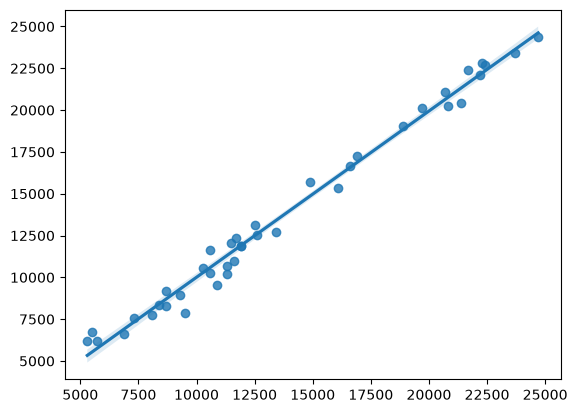

In [115]:
sns.regplot(x=y_test, y=y_pred_poly);

In [116]:
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 

coef_ridge = []
err_ridge = []
baseline = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_poly, y_train)
    
    coef_ridge.append(ridge.coef_)
    
    y_pred = ridge.predict(X_test_poly)
    ridge_error = mean_squared_error(y_pred, y_test)
    
    err_ridge.append(ridge_error)
    baseline.append(baseline_error)

In [117]:
min(err_ridge)

409511.1703780827

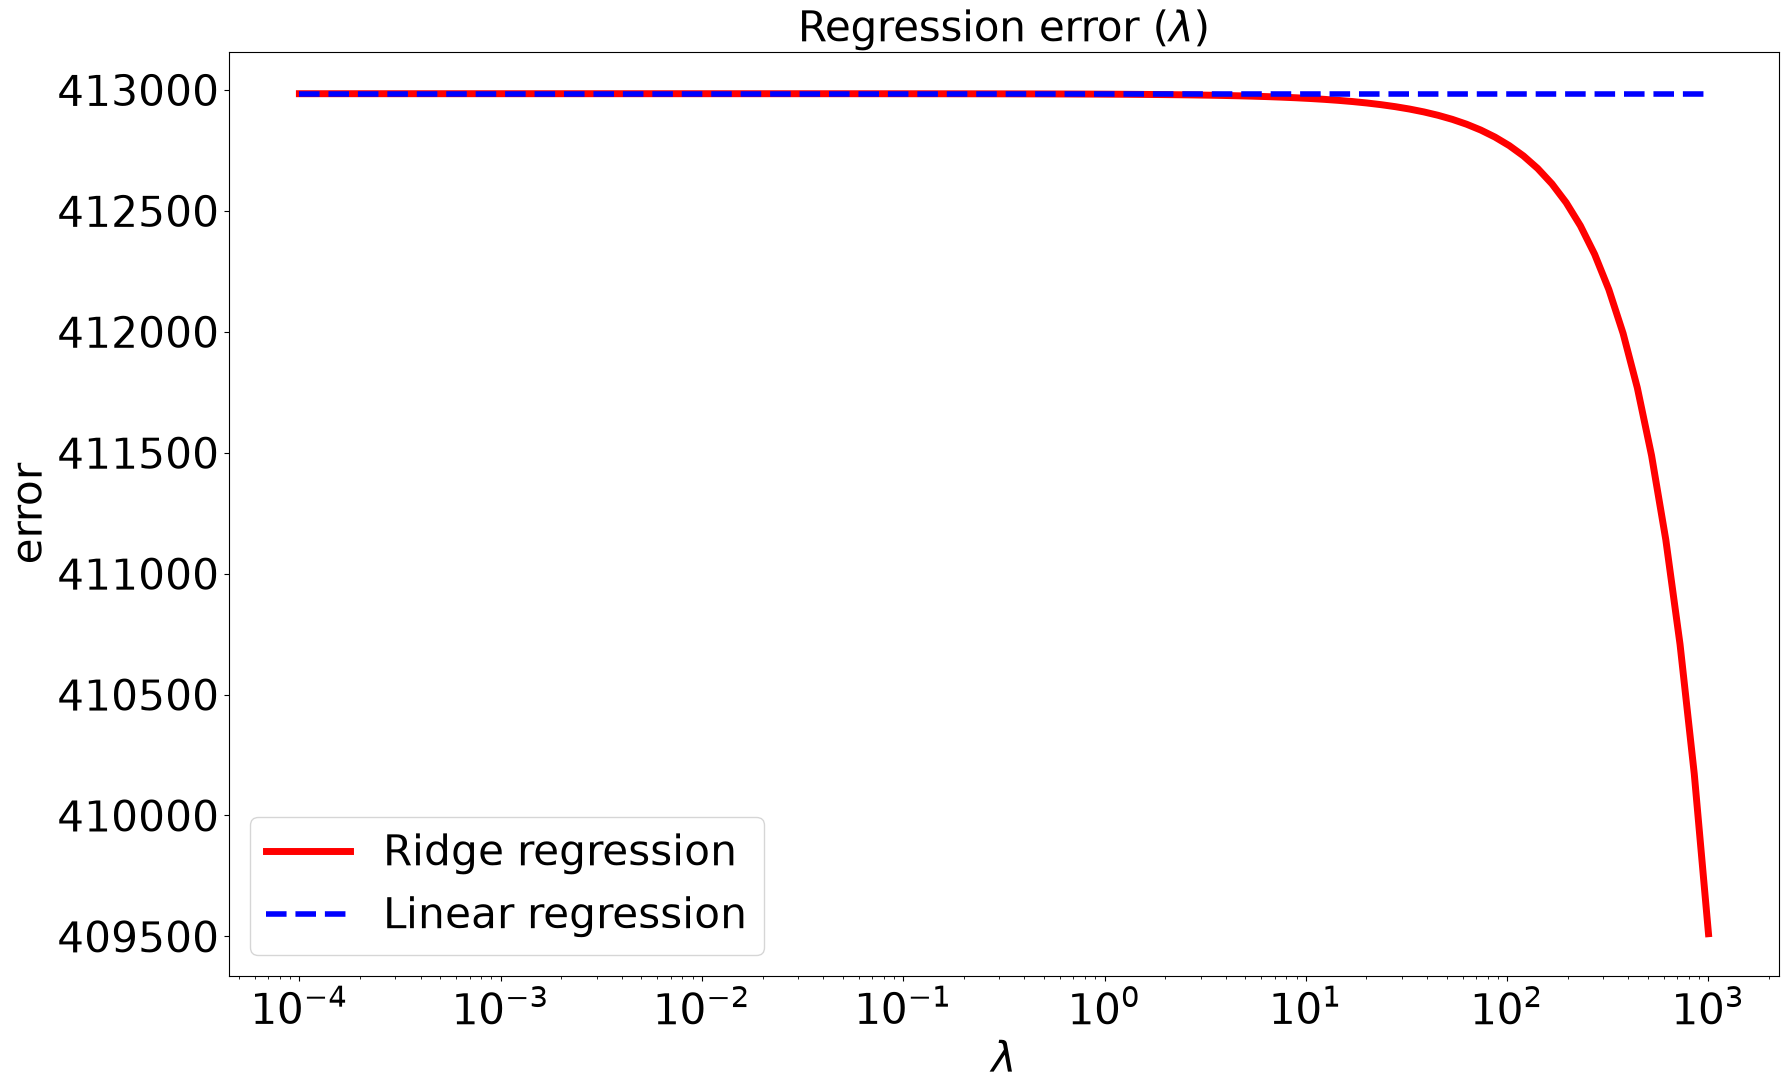

In [118]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [119]:
from sklearn.linear_model import Ridge

ridgeR = Ridge(alpha = 1000) # Alpha muy pequeñito
ridgeR.fit(X_poly, y_train)


print("Train MSE sin regularización:", round(mean_squared_error(y_train, lm.predict(X_train)),2))
print("Test MSE sin regularización:", round(mean_squared_error(y_test, lm.predict(X_test)),2))

print("r2_score train", r2_score(y_train, lm.predict(X_train)))

print("Train MSE con regularización:", round(mean_squared_error(y_train, ridgeR.predict(X_poly)),2))
print("Test MSE con regularización:", round(mean_squared_error(y_test, ridgeR.predict(X_test_poly)),2))
# print("Test RMSE:", np.sqrt(metrics.mean_squared_error(y_test, ridgeR.predict(X_test))))

print("r2_score train", r2_score(y_train, ridgeR.predict(X_poly)))

Train MSE sin regularización: 2705093.44
Test MSE sin regularización: 3174361.93
r2_score train 0.8957022145868812
Train MSE con regularización: 361179.64
Test MSE con regularización: 409511.17
r2_score train 0.9860743308129976


In [120]:
from sklearn.linear_model import Lasso

lassoR = Lasso(alpha=0.1)
lassoR.fit(X_poly, y_train)

print("Train MSE sin regularización:", round(mean_squared_error(y_train, lm.predict(X_train)),2))
print("Test MSE sin regularización:", round(mean_squared_error(y_test, lm.predict(X_test)),2))

print("Train MSE: %0.4f" % mean_squared_error(y_train, lassoR.predict(X_poly)))
print("Test MSE: %0.4f" % mean_squared_error(y_test, lassoR.predict(X_test_poly)))

Train MSE sin regularización: 2705093.44
Test MSE sin regularización: 3174361.93
Train MSE: 360390.1165
Test MSE: 412986.3686


In [ ]:
lasso = Lasso()

coef_lasso = []
err_lasso = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_poly, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred = lasso.predict(X_test_poly)
    lasso_error = mean_squared_error(y_pred, y_test)    
    err_lasso.append(lasso_error)

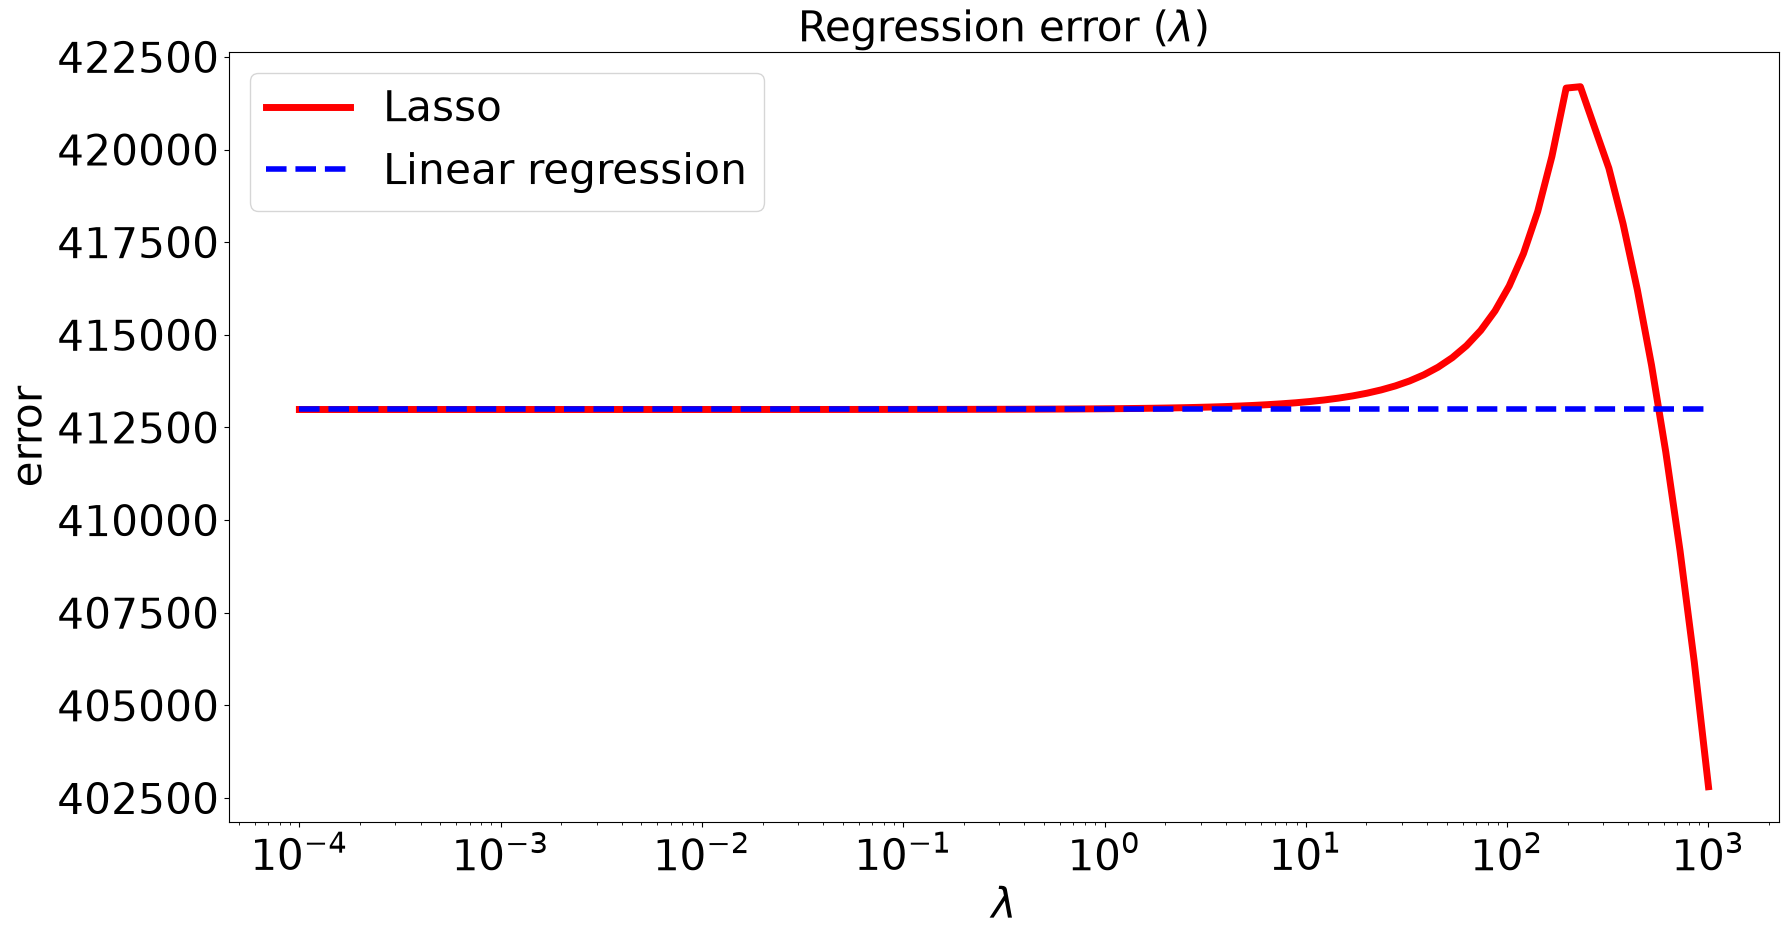

In [122]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [123]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha = 1, l1_ratio = 0.5)
elastic_net.fit(X_poly, y_train)

print("Train MSE sin regularización:", round(mean_squared_error(y_train, lm.predict(X_train)),2))
print("Test MSE sin regularización:", round(mean_squared_error(y_test, lm.predict(X_test)),2))

print("Train MSE: %0.4f" % mean_squared_error(y_train, elastic_net.predict(X_poly)))
print("Test MSE: %0.4f" % mean_squared_error(y_test, elastic_net.predict(X_test_poly)))

Train MSE sin regularización: 2705093.44
Test MSE sin regularización: 3174361.93
Train MSE: 360399.4336
Test MSE: 412830.0732


In [124]:
coef_eln = []
err_eln = []
baseline = []
for a in alphas:
    elastic_net = ElasticNet(alpha = a, l1_ratio=0.5)
    elastic_net.fit(X_train, y_train)
    coef_eln.append(elastic_net.coef_)
    y_pred = elastic_net.predict(X_test)
    elasticnet_error = mean_squared_error(y_pred, y_test)
    err_eln.append(elasticnet_error)
    baseline.append(baseline_error)

In [125]:
min(err_eln)

3174145.4050611174

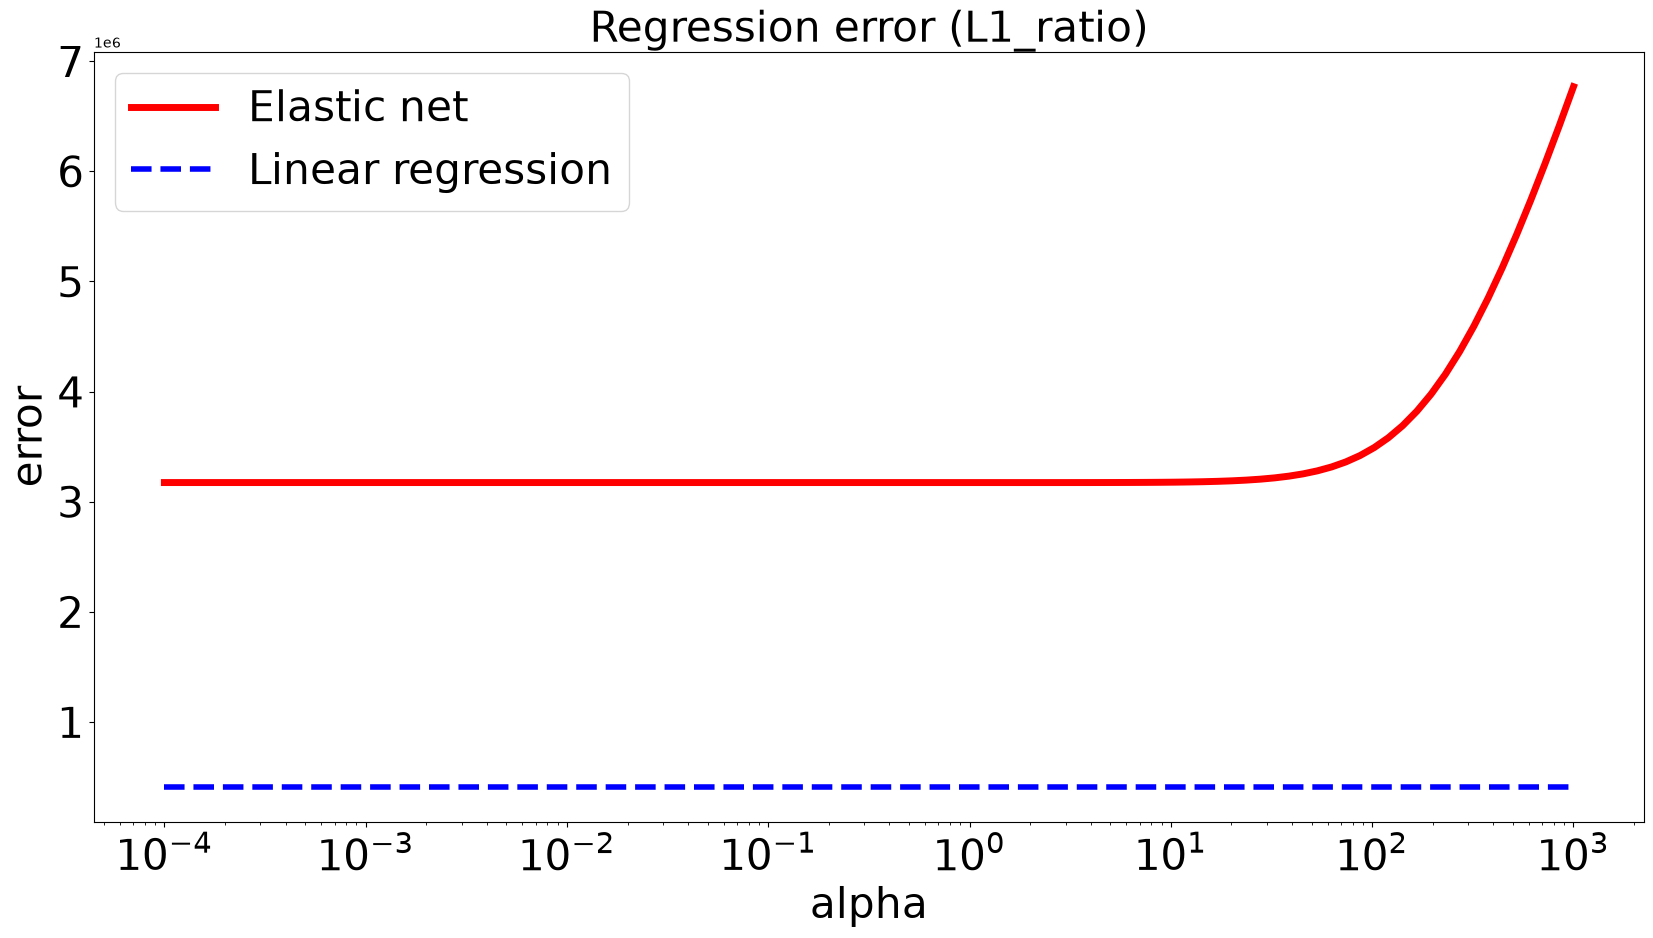

In [126]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_eln, linewidth=5, color='red', label="Elastic net")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel('alpha', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error (L1_ratio)', fontsize=30)
plt.show()

In [127]:
elastic_net = ElasticNet(alpha = 0.08, l1_ratio=1)
elastic_net.fit(X_poly, y_train) 

print("Train MSE: %0.4f" % mean_squared_error(y_train, elastic_net.predict(X_poly)))
print("Test MSE: %0.4f" % mean_squared_error(y_test, elastic_net.predict(X_test_poly)))

Train MSE: 360390.1161
Test MSE: 412985.9817


## Resultados

In [128]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [88]:
print("Linear regression error:   %0.4f" % baseline_error)    
print("Minimun ridge error:       %0.4f" % min(err_ridge))
print("Minimum lasso error:       %0.4f" % min(err_lasso))
print("Minimum elastic net error: %0.4f" % min(err_eln))

Linear regression error:   412984.4376
Minimun ridge error:       409511.1704
Minimum lasso error:       413045.5040
Minimum elastic net error: 3174145.4051
